# 🔬 Multi-Class Benchmark Classification Pipeline
**Iris (CSV) & Wine (sklearn) | Logistic Regression vs Decision Tree**

---

| Step | Description |
|------|-------------|
| 1 | Load **Iris** from `iris.csv` (user-supplied) · **Wine** from sklearn |
| 2 | Exploratory Data Analysis with Seaborn pairplots |
| 3 | Feature scaling with `StandardScaler` |
| 4 | 80/20 stratified train/test split |
| 5 | Train `LogisticRegression` and `DecisionTreeClassifier` |
| 6 | Benchmark: accuracy, precision, recall, F1-score |
| 7 | Confusion matrix heatmaps |
| 8 | Decision boundary visualization (PCA 2-D) |
| 9 | Decision Tree structure diagram |
| 10 | Feature importances |


In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import types
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from matplotlib.colors import ListedColormap

# ── Global dark-mode plot style ───────────────────────────────────────────────
sns.set_theme(style='darkgrid', palette='Set2', font_scale=1.1)
plt.rcParams.update({
    'figure.dpi': 120, 'figure.facecolor': '#0f0f1a',
    'axes.facecolor': '#1a1a2e', 'axes.edgecolor': '#444',
    'grid.color': '#333', 'text.color': '#e0e0e0',
    'axes.labelcolor': '#e0e0e0', 'xtick.color': '#e0e0e0',
    'ytick.color': '#e0e0e0', 'axes.titlecolor': '#ffffff'
})

RANDOM_STATE = 42
print('✅ All libraries imported successfully')

✅ All libraries imported successfully


---
## 1 · Dataset Loading

In [2]:
# ── 1a. Iris — load from user-supplied CSV ────────────────────────────────────
iris_df = pd.read_csv('iris.csv')

# Encode string labels → integer targets (alphabetical order)
iris_class_names = sorted(iris_df['species'].unique())
iris_label_map   = {name: i for i, name in enumerate(iris_class_names)}
iris_df['target'] = iris_df['species'].map(iris_label_map)

IRIS_FEATURE_COLS = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

# Lightweight Bunch-compatible namespace so the pipeline code is uniform
iris_bunch = types.SimpleNamespace(
    feature_names = IRIS_FEATURE_COLS,
    target_names  = iris_class_names,
)

print('═' * 55)
print('IRIS DATASET  (source: iris.csv)')
print('═' * 55)
print(f'Shape : {iris_df.shape}')
print(f'Classes: {iris_class_names}')
print(f'Class distribution:\n{iris_df["species"].value_counts().to_string()}\n')
display(iris_df.describe().round(3))

═══════════════════════════════════════════════════════
IRIS DATASET  (source: iris.csv)
═══════════════════════════════════════════════════════
Shape : (150, 6)
Classes: ['setosa', 'versicolor', 'virginica']
Class distribution:
species
setosa        50
versicolor    50
virginica     50



,sepal_length,sepal_width,petal_length,petal_width,target
count,150.000,150.000,150.000,150.000,150.000
mean,5.843,3.057,3.758,1.199,1.000
std,0.828,0.436,1.765,0.762,0.819
min,4.300,2.000,1.000,0.100,0.000
25%,5.100,2.800,1.600,0.300,0.000
50%,5.800,3.000,4.350,1.300,1.000
75%,6.400,3.300,5.100,1.800,2.000
max,7.900,4.400,6.900,2.500,2.000


In [3]:
# ── 1b. Wine — load from sklearn ──────────────────────────────────────────────
def sklearn_to_df(loader):
    """Convert a sklearn Bunch into a tidy DataFrame."""
    b = loader()
    df = pd.DataFrame(b.data, columns=b.feature_names)
    df['target']  = b.target
    df['species'] = [b.target_names[t] for t in b.target]
    return df, b

wine_df, wine_bunch = sklearn_to_df(load_wine)

print('═' * 55)
print('WINE DATASET  (source: sklearn)')
print('═' * 55)
print(f'Shape : {wine_df.shape}')
print(f'Classes: {list(wine_bunch.target_names)}')
print(f'Class distribution:\n{wine_df["species"].value_counts().to_string()}')
display(wine_df.describe().round(3))

═══════════════════════════════════════════════════════
WINE DATASET  (source: sklearn)
═══════════════════════════════════════════════════════
Shape : (178, 15)
Classes: ['class_0', 'class_1', 'class_2']
Class distribution:
species
class_1    71
class_0    59
class_2    48


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000
mean,13.001,2.336,2.367,19.495,99.742,2.295,2.029,0.362,1.591,5.058,0.957,2.612,746.893,0.938
std,0.812,1.117,0.274,3.340,14.282,0.626,0.999,0.124,0.572,2.318,0.229,0.710,314.907,0.775
min,11.030,0.740,1.360,10.600,70.000,0.980,0.340,0.130,0.410,1.280,0.480,1.270,278.000,0.000
25%,12.362,1.602,2.210,17.200,88.000,1.742,1.205,0.270,1.250,3.220,0.782,1.938,500.500,0.000
50%,13.050,1.865,2.360,19.500,98.000,2.355,2.135,0.340,1.555,4.690,0.965,2.780,673.500,1.000
75%,13.678,3.082,2.558,21.500,107.000,2.800,2.875,0.438,1.950,6.200,1.120,3.170,985.000,2.000
max,14.830,5.800,3.230,30.000,162.000,3.880,5.080,0.660,3.580,13.000,1.710,4.000,1680.000,2.000


---
## 2 · Exploratory Data Analysis (EDA)

C:\Users\Start\AppData\Local\Temp\ipykernel_16684\579972955.py:21: UserWarning: Glyph 127800 (\N{CHERRY BLOSSOM}) missing from current font.
  plt.tight_layout()


C:\Users\Start\AppData\Local\Temp\ipykernel_16684\579972955.py:22: UserWarning: Glyph 127800 (\N{CHERRY BLOSSOM}) missing from current font.
  plt.savefig('iris_pairplot.png', bbox_inches='tight', facecolor='#0f0f1a')


C:\Users\Start\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127800 (\N{CHERRY BLOSSOM}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


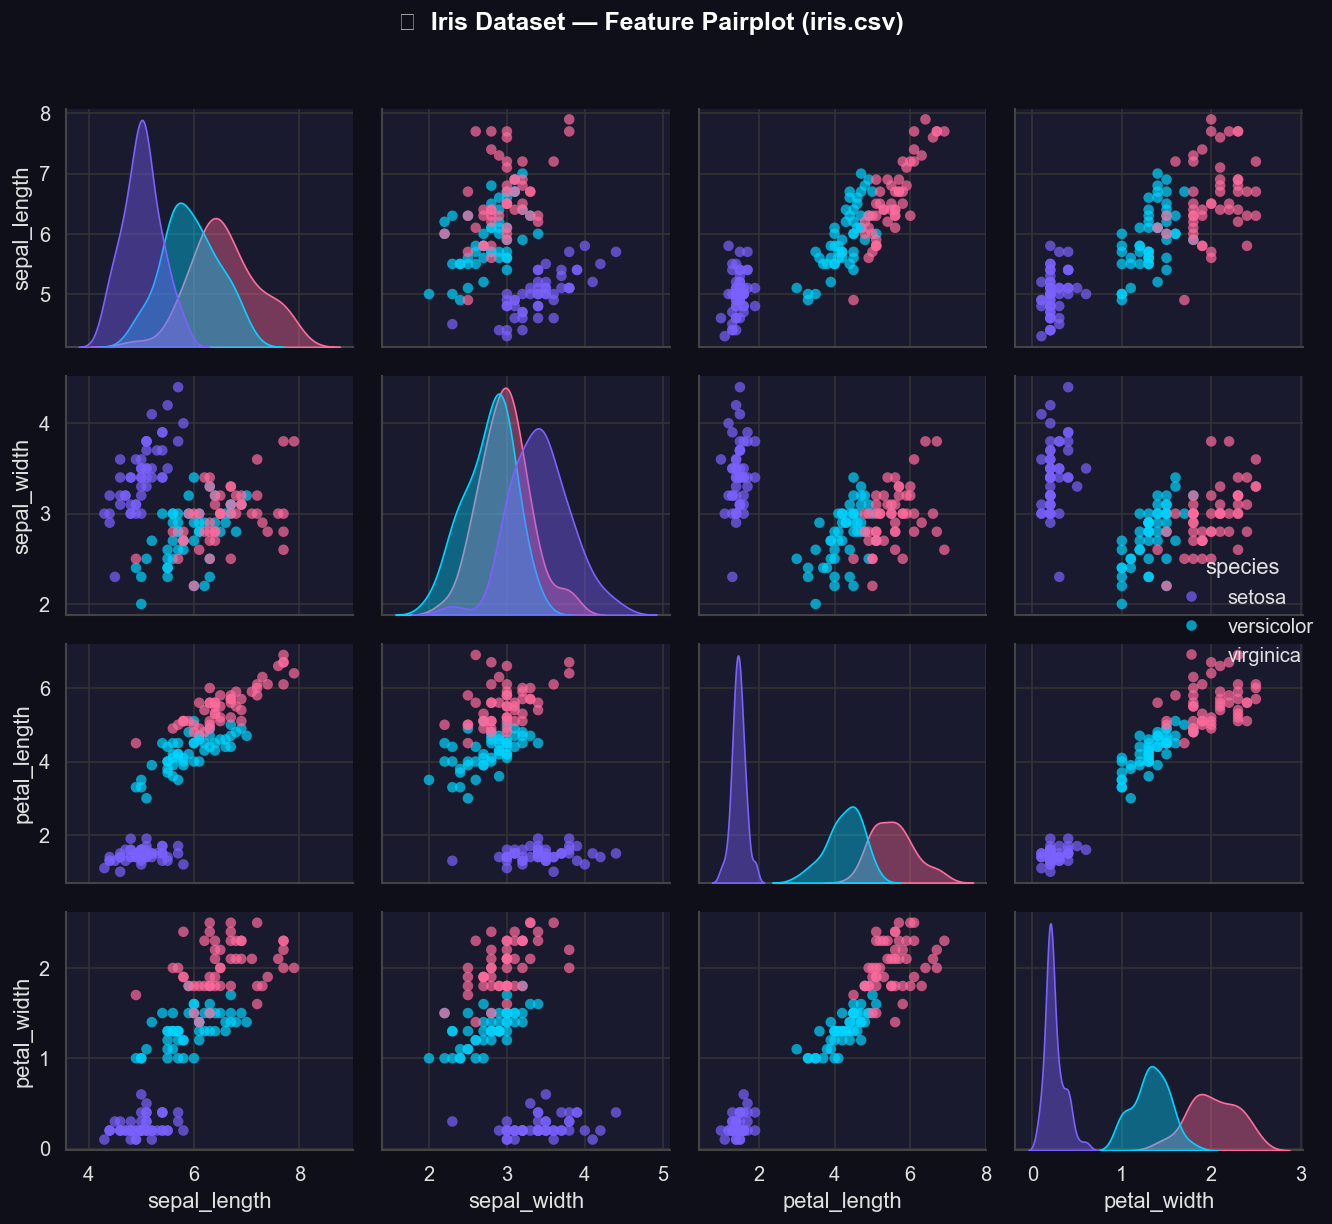

Saved → iris_pairplot.png


In [4]:
# ── Iris Pairplot ─────────────────────────────────────────────────────────────
IRIS_PALETTE = {'setosa': '#7B61FF', 'versicolor': '#00D4FF', 'virginica': '#FF6B9D'}

g = sns.pairplot(
    iris_df[IRIS_FEATURE_COLS + ['species']],
    hue='species',
    palette=IRIS_PALETTE,
    diag_kind='kde',
    plot_kws=dict(alpha=0.7, s=40, edgecolors='none'),
    diag_kws=dict(fill=True, alpha=0.4)
)
g.figure.patch.set_facecolor('#0f0f1a')
for ax in g.axes.flatten():
    if ax:
        ax.set_facecolor('#1a1a2e')
        for spine in ax.spines.values():
            spine.set_edgecolor('#444')

g.figure.suptitle('🌸  Iris Dataset — Feature Pairplot (iris.csv)', y=1.02,
                   fontsize=15, fontweight='bold', color='white')
plt.tight_layout()
plt.savefig('iris_pairplot.png', bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
print('Saved → iris_pairplot.png')

C:\Users\Start\AppData\Local\Temp\ipykernel_16684\397494381.py:22: UserWarning: Glyph 127863 (\N{WINE GLASS}) missing from current font.
  plt.tight_layout()


C:\Users\Start\AppData\Local\Temp\ipykernel_16684\397494381.py:23: UserWarning: Glyph 127863 (\N{WINE GLASS}) missing from current font.
  plt.savefig('wine_pairplot.png', bbox_inches='tight', facecolor='#0f0f1a')


C:\Users\Start\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127863 (\N{WINE GLASS}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


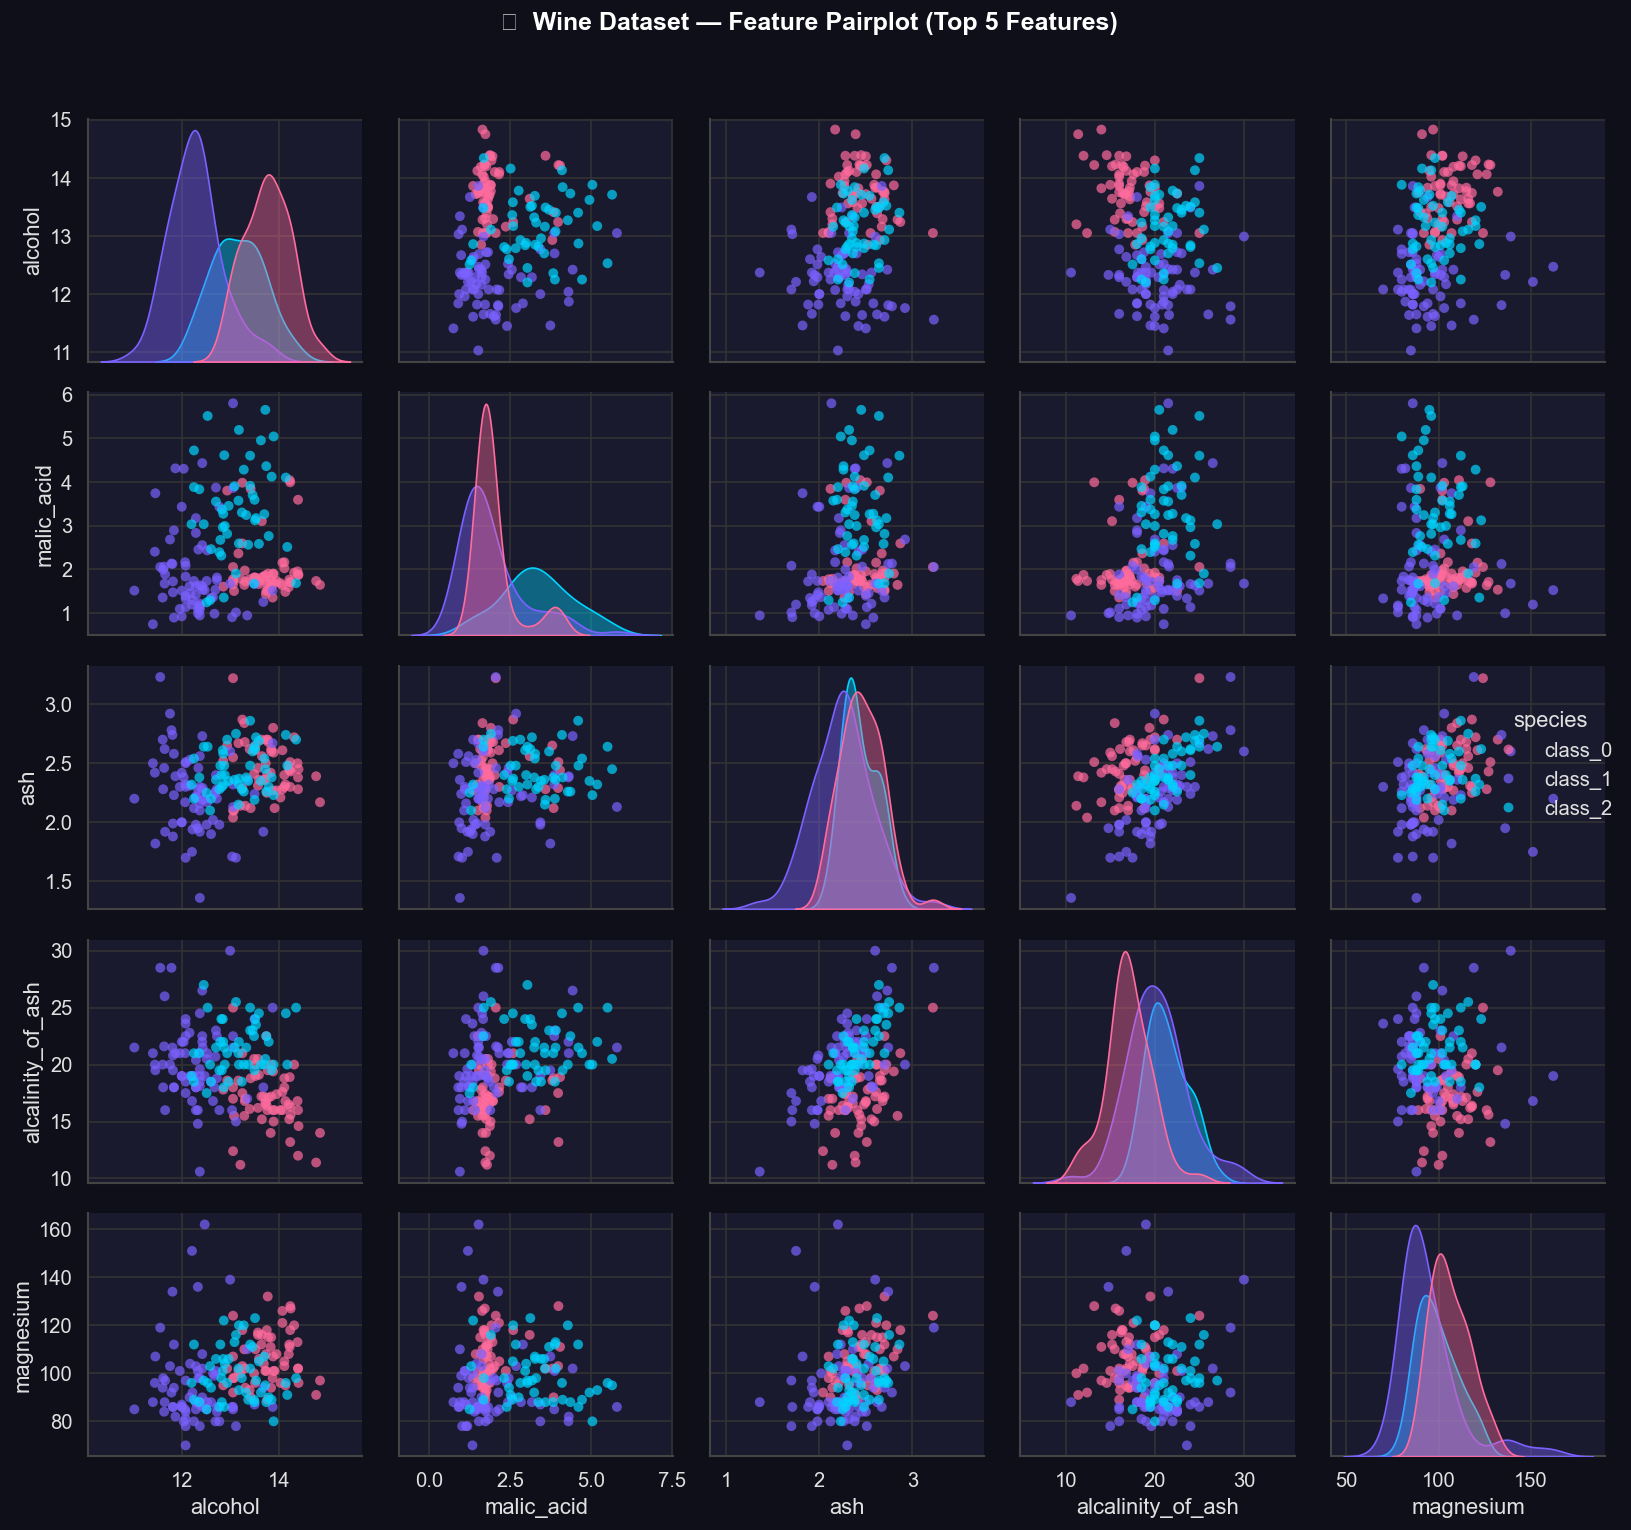

Saved → wine_pairplot.png


In [5]:
# ── Wine Pairplot (first 5 features for readability) ──────────────────────────
WINE_PALETTE = {'class_0': '#FF6B9D', 'class_1': '#7B61FF', 'class_2': '#00D4FF'}

wine_plot_cols = list(wine_bunch.feature_names[:5]) + ['species']
g2 = sns.pairplot(
    wine_df[wine_plot_cols],
    hue='species',
    palette=WINE_PALETTE,
    diag_kind='kde',
    plot_kws=dict(alpha=0.7, s=35, edgecolors='none'),
    diag_kws=dict(fill=True, alpha=0.4)
)
g2.figure.patch.set_facecolor('#0f0f1a')
for ax in g2.axes.flatten():
    if ax:
        ax.set_facecolor('#1a1a2e')
        for spine in ax.spines.values():
            spine.set_edgecolor('#444')

g2.figure.suptitle('🍷  Wine Dataset — Feature Pairplot (Top 5 Features)', y=1.02,
                    fontsize=15, fontweight='bold', color='white')
plt.tight_layout()
plt.savefig('wine_pairplot.png', bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
print('Saved → wine_pairplot.png')

---
## 3 · Preprocessing — StandardScaler + 80/20 Split

In [6]:
def prepare_data(df, bunch):
    """
    Returns X_train, X_test, y_train, y_test (scaled) and the fitted scaler.
    Works with both sklearn Bunch objects and SimpleNamespace objects.
    Split: 80% train / 20% test, stratified.
    """
    X = df[bunch.feature_names].values
    y = df['target'].values

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
    )

    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc  = scaler.transform(X_test)

    print(f'  Train : {X_train_sc.shape[0]:>4} samples')
    print(f'  Test  : {X_test_sc.shape[0]:>4} samples')
    print(f'  Feats : {X_train_sc.shape[1]:>4}')
    return X_train_sc, X_test_sc, y_train, y_test, scaler

print('── IRIS ──')
iris_X_train, iris_X_test, iris_y_train, iris_y_test, iris_scaler = prepare_data(iris_df, iris_bunch)

print('\n── WINE ──')
wine_X_train, wine_X_test, wine_y_train, wine_y_test, wine_scaler = prepare_data(wine_df, wine_bunch)

── IRIS ──
  Train :  120 samples
  Test  :   30 samples
  Feats :    4

── WINE ──
  Train :  142 samples
  Test  :   36 samples
  Feats :   13


---
## 4 · Model Training

In [7]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tree':       DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
}

datasets = {
    'Iris': (iris_X_train, iris_X_test, iris_y_train, iris_y_test, iris_bunch),
    'Wine': (wine_X_train, wine_X_test, wine_y_train, wine_y_test, wine_bunch)
}

trained     = {ds: {} for ds in datasets}
predictions = {ds: {} for ds in datasets}

for ds_name, (X_tr, X_te, y_tr, y_te, bunch) in datasets.items():
    print(f'\n── {ds_name} ──')
    for model_name, model in models.items():
        m = copy.deepcopy(model)
        m.fit(X_tr, y_tr)
        y_pred = m.predict(X_te)
        trained[ds_name][model_name]     = m
        predictions[ds_name][model_name] = y_pred
        acc = accuracy_score(y_te, y_pred)
        print(f'  {model_name:<22} → test accuracy = {acc:.4f}')

print('\n✅ All models trained.')


── Iris ──
  Logistic Regression    → test accuracy = 0.9333
  Decision Tree          → test accuracy = 0.9333

── Wine ──
  Logistic Regression    → test accuracy = 0.9722
  Decision Tree          → test accuracy = 0.9444

✅ All models trained.


---
## 5 · Benchmark Metrics (Accuracy · Precision · Recall · F1)

In [8]:
rows = []
for ds_name, (X_tr, X_te, y_tr, y_te, bunch) in datasets.items():
    for model_name in models:
        y_pred = predictions[ds_name][model_name]
        rows.append({
            'Dataset':   ds_name,
            'Model':     model_name,
            'Accuracy':  round(accuracy_score(y_te, y_pred), 4),
            'Precision': round(precision_score(y_te, y_pred, average='weighted', zero_division=0), 4),
            'Recall':    round(recall_score(y_te, y_pred, average='weighted', zero_division=0), 4),
            'F1-Score':  round(f1_score(y_te, y_pred, average='weighted', zero_division=0), 4),
        })

metrics_df = pd.DataFrame(rows)
display(metrics_df.style
    .background_gradient(subset=['Accuracy','Precision','Recall','F1-Score'], cmap='YlOrRd')
    .set_caption('Model Benchmark Metrics (Weighted Average)')
    .format({'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}', 'F1-Score': '{:.4f}'})
)

,Dataset,Model,Accuracy,Precision,Recall,F1-Score
0,Iris,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Iris,Decision Tree,0.9333,0.9333,0.9333,0.9333
2,Wine,Logistic Regression,0.9722,0.9741,0.9722,0.9720
3,Wine,Decision Tree,0.9444,0.9514,0.9444,0.9450


In [9]:
# ── Per-class Classification Reports ──────────────────────────────────────────
for ds_name, (X_tr, X_te, y_tr, y_te, bunch) in datasets.items():
    print('\n' + '═'*60)
    print(f'  {ds_name.upper()} DATASET — Classification Reports')
    print('═'*60)
    for model_name in models:
        y_pred = predictions[ds_name][model_name]
        print(f'\n  ▶  {model_name}')
        print(classification_report(y_te, y_pred,
                                    target_names=bunch.target_names,
                                    digits=4))


════════════════════════════════════════════════════════════
  IRIS DATASET — Classification Reports
════════════════════════════════════════════════════════════

  ▶  Logistic Regression
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30


  ▶  Decision Tree
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30


════════════════════════════

---
## 6 · Confusion Matrix Heatmaps

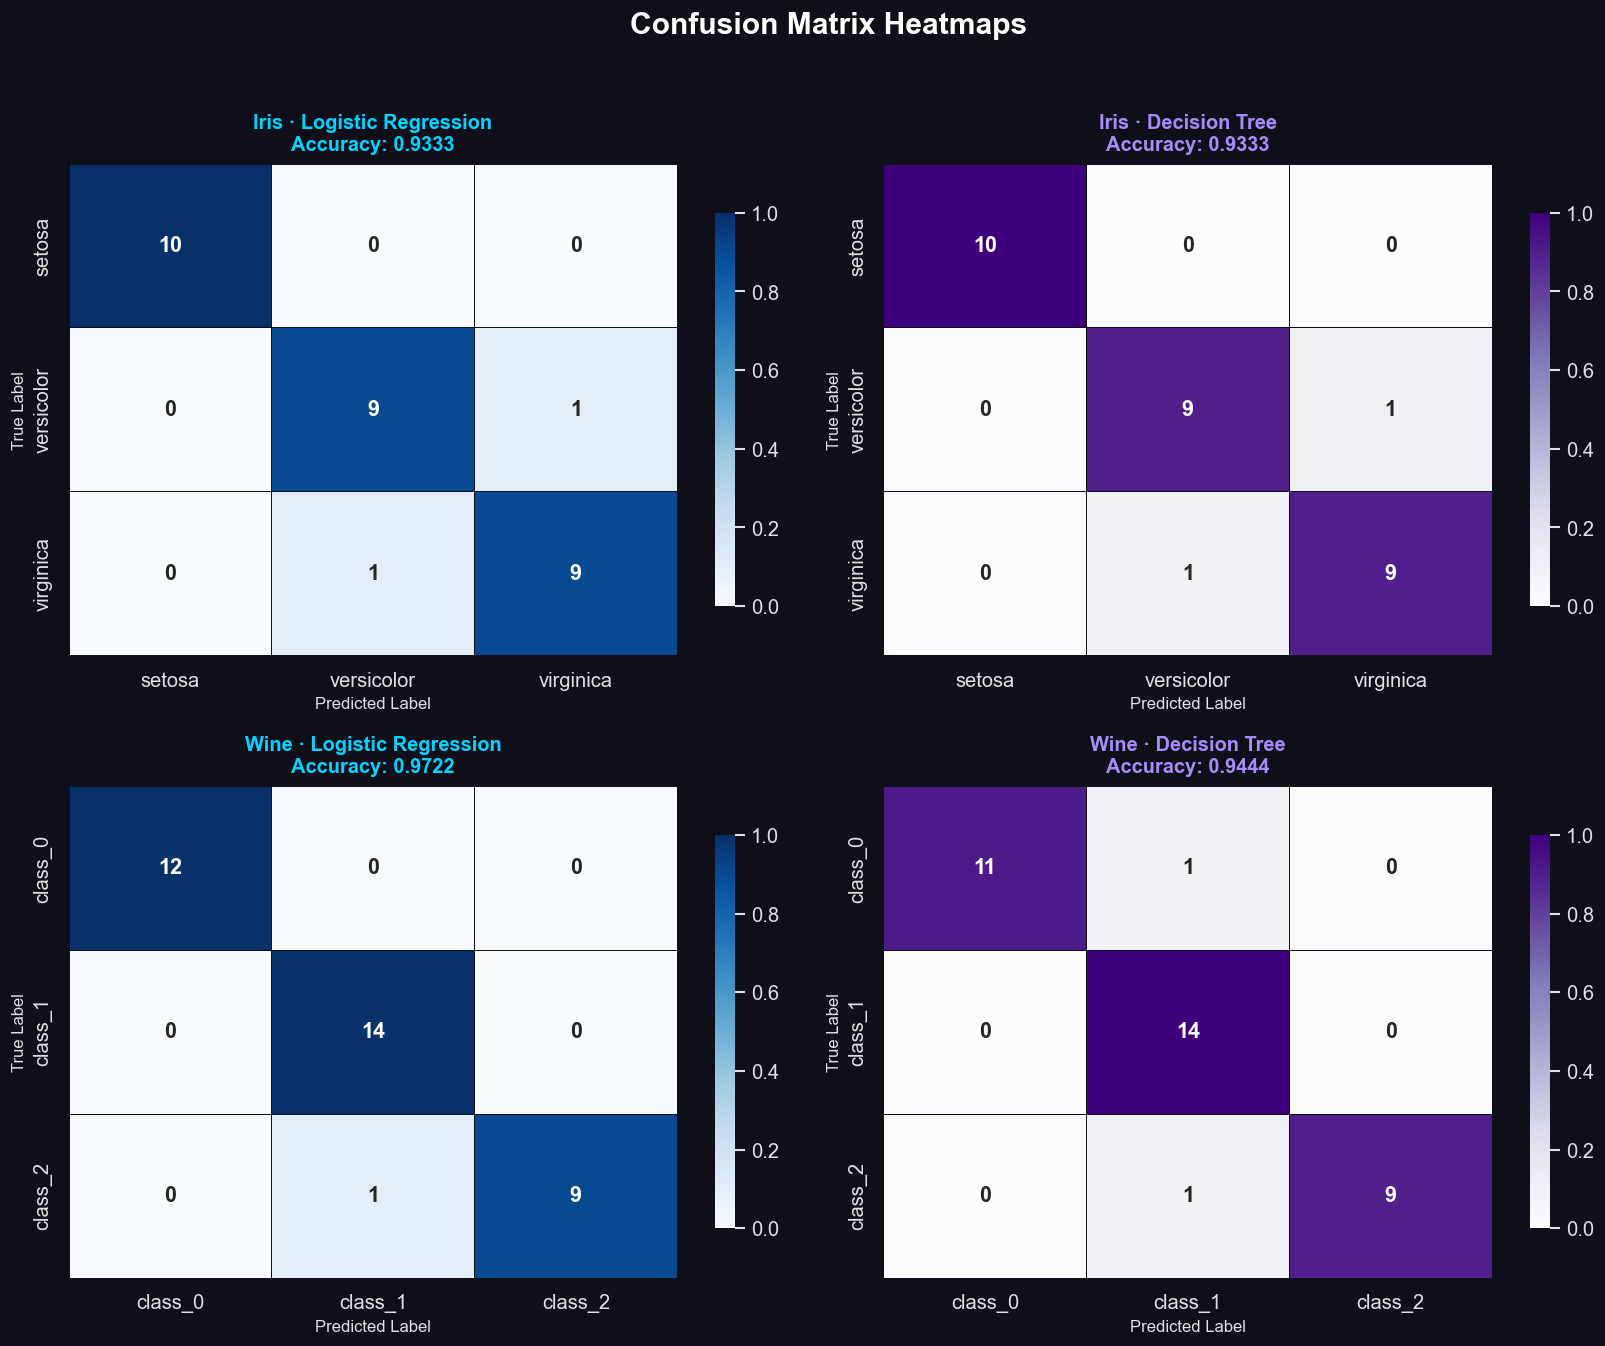

Saved → confusion_matrices.png


In [10]:
CMAPS        = {'Logistic Regression': 'Blues',  'Decision Tree': 'Purples'}
TITLE_COLORS = {'Logistic Regression': '#00D4FF', 'Decision Tree': '#A78BFA'}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
fig.patch.set_facecolor('#0f0f1a')
fig.suptitle('Confusion Matrix Heatmaps', fontsize=18, fontweight='bold',
             color='white', y=1.02)

for row_idx, (ds_name, (X_tr, X_te, y_tr, y_te, bunch)) in enumerate(datasets.items()):
    for col_idx, model_name in enumerate(models):
        ax     = axes[row_idx][col_idx]
        y_pred = predictions[ds_name][model_name]
        cm     = confusion_matrix(y_te, y_pred)
        cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

        labels = list(bunch.target_names)
        sns.heatmap(
            cm_norm, annot=cm, fmt='d', ax=ax,
            cmap=CMAPS[model_name],
            xticklabels=labels, yticklabels=labels,
            linewidths=0.5, linecolor='#0f0f1a',
            cbar_kws={'shrink': 0.8},
            annot_kws={'size': 13, 'weight': 'bold'}
        )
        acc = accuracy_score(y_te, y_pred)
        ax.set_title(f'{ds_name} · {model_name}\nAccuracy: {acc:.4f}',
                     color=TITLE_COLORS[model_name], fontsize=12, fontweight='bold', pad=8)
        ax.set_xlabel('Predicted Label', color='#e0e0e0', fontsize=10)
        ax.set_ylabel('True Label', color='#e0e0e0', fontsize=10)
        ax.tick_params(colors='#e0e0e0')
        ax.set_facecolor('#1a1a2e')
        for spine in ax.spines.values():
            spine.set_edgecolor('#444')

plt.tight_layout()
plt.savefig('confusion_matrices.png', bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
print('Saved → confusion_matrices.png')

---
## 7 · Metric Comparison Bar Charts

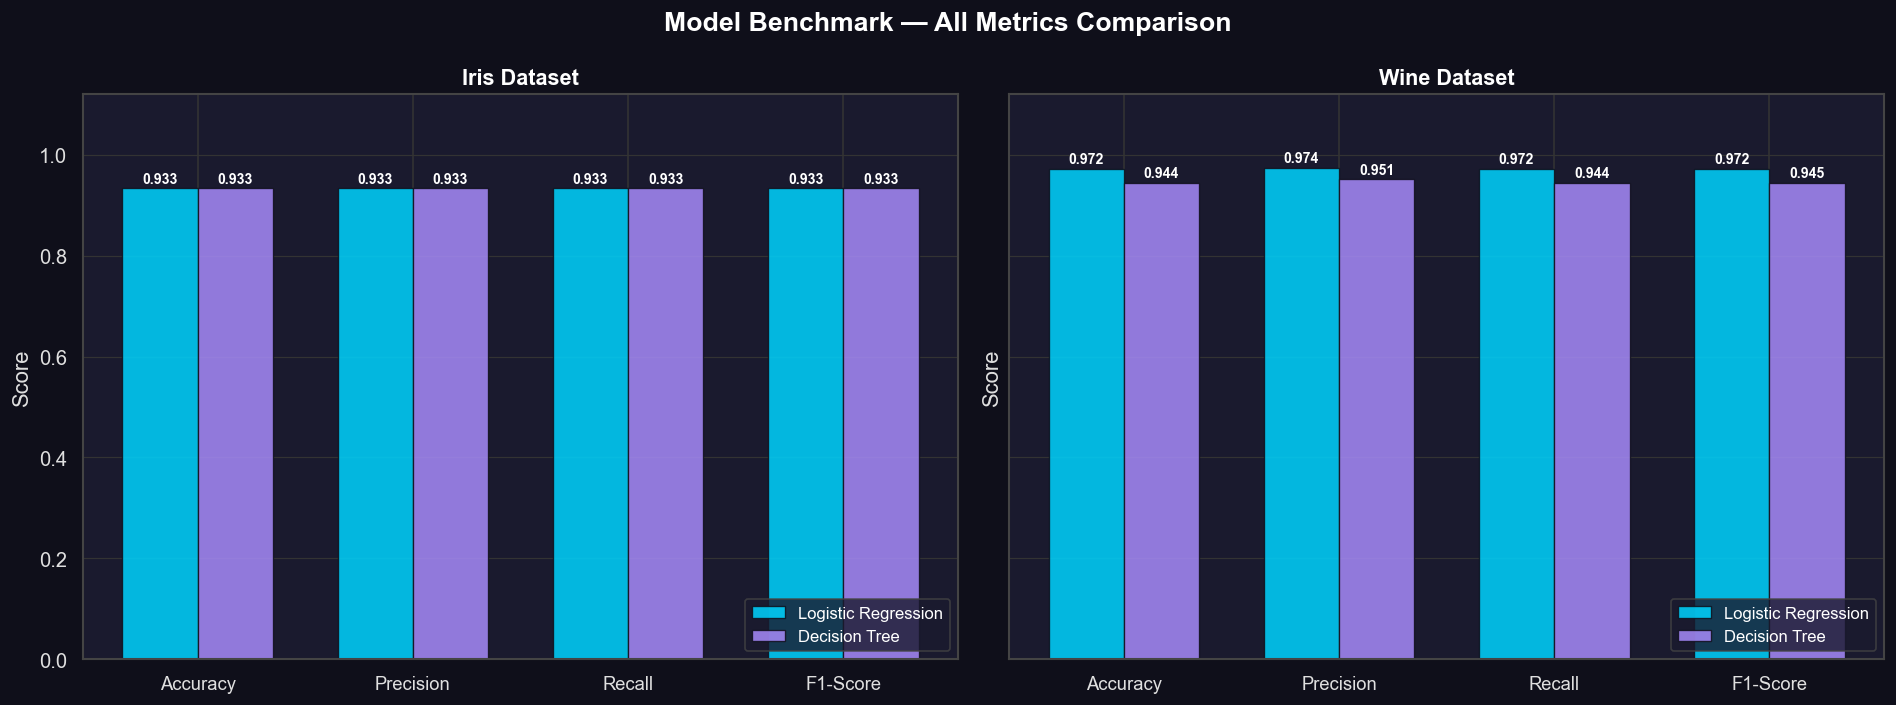

Saved → metrics_comparison.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
fig.patch.set_facecolor('#0f0f1a')
fig.suptitle('Model Benchmark — All Metrics Comparison', fontsize=16,
             fontweight='bold', color='white')

metric_cols  = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x            = np.arange(len(metric_cols))
width        = 0.35
model_colors = {'Logistic Regression': '#00D4FF', 'Decision Tree': '#A78BFA'}

for ax_idx, ds_name in enumerate(['Iris', 'Wine']):
    ax = axes[ax_idx]
    ax.set_facecolor('#1a1a2e')
    for spine in ax.spines.values():
        spine.set_edgecolor('#444')

    subset = metrics_df[metrics_df['Dataset'] == ds_name]
    for m_idx, (model_name, color) in enumerate(model_colors.items()):
        vals   = subset[subset['Model'] == model_name][metric_cols].values.flatten()
        offset = (m_idx - 0.5) * width
        bars   = ax.bar(x + offset, vals, width, label=model_name,
                        color=color, alpha=0.85, edgecolor='#0f0f1a', linewidth=0.8)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                    f'{val:.3f}', ha='center', va='bottom',
                    fontsize=8.5, color='white', fontweight='bold')

    ax.set_title(f'{ds_name} Dataset', color='white', fontsize=13, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(metric_cols, color='#e0e0e0', fontsize=11)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel('Score', color='#e0e0e0')
    ax.tick_params(colors='#e0e0e0')
    ax.legend(facecolor='#1a1a2e', edgecolor='#444', labelcolor='white',
              fontsize=10, loc='lower right')
    ax.yaxis.grid(True, color='#333', linewidth=0.7)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('metrics_comparison.png', bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
print('Saved → metrics_comparison.png')

---
## 8 · Decision Boundary Visualization

Features are reduced to **2 PCA components** for 2-D boundary visualization.

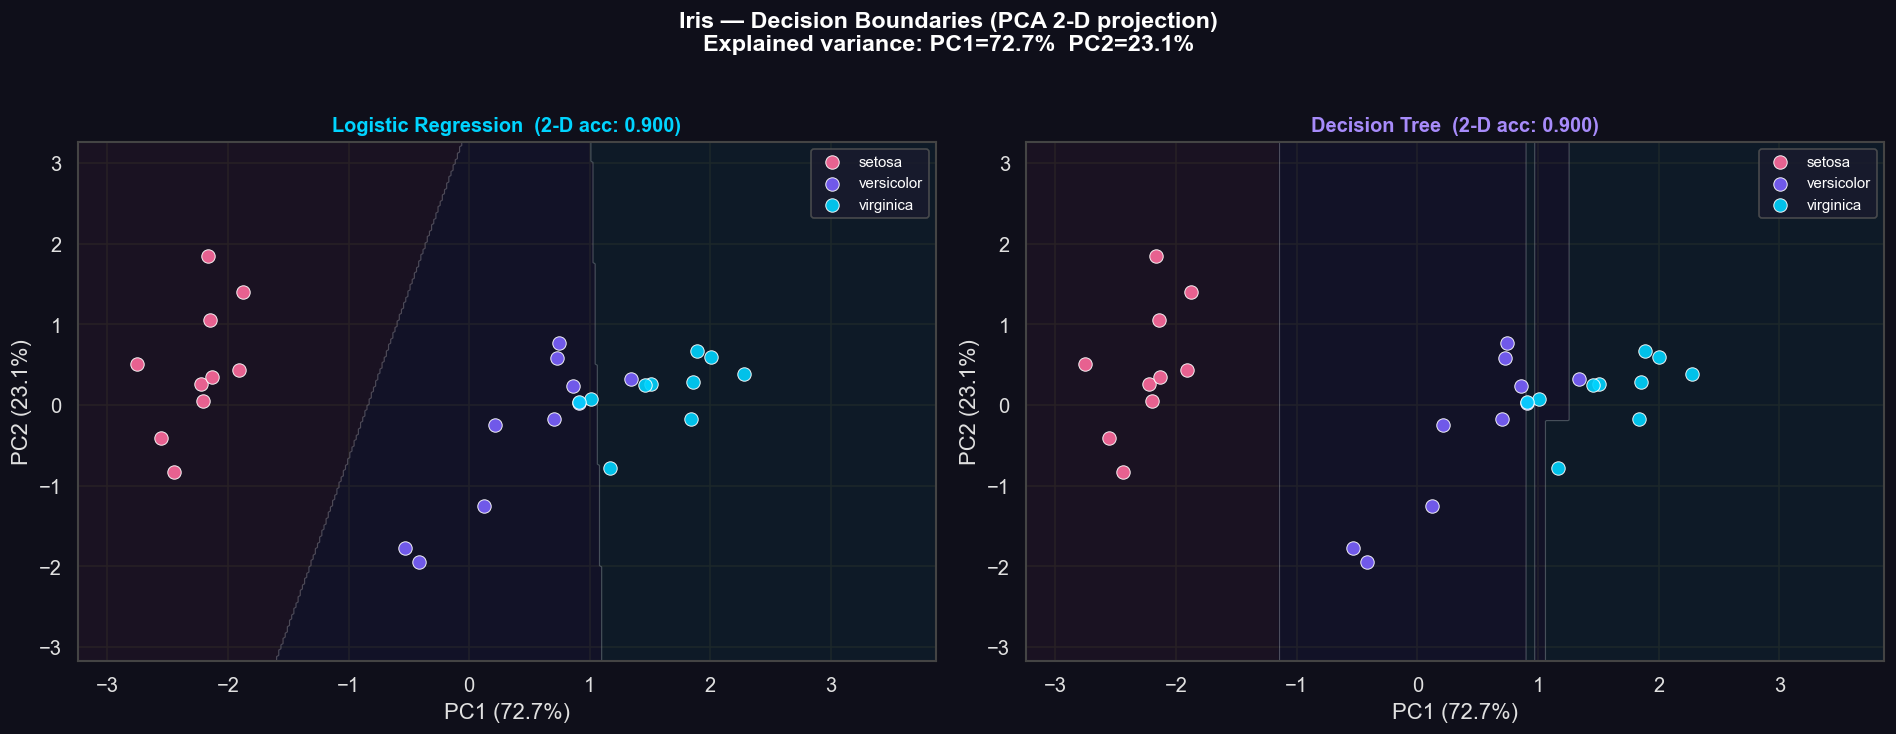

Saved → iris_decision_boundaries.png


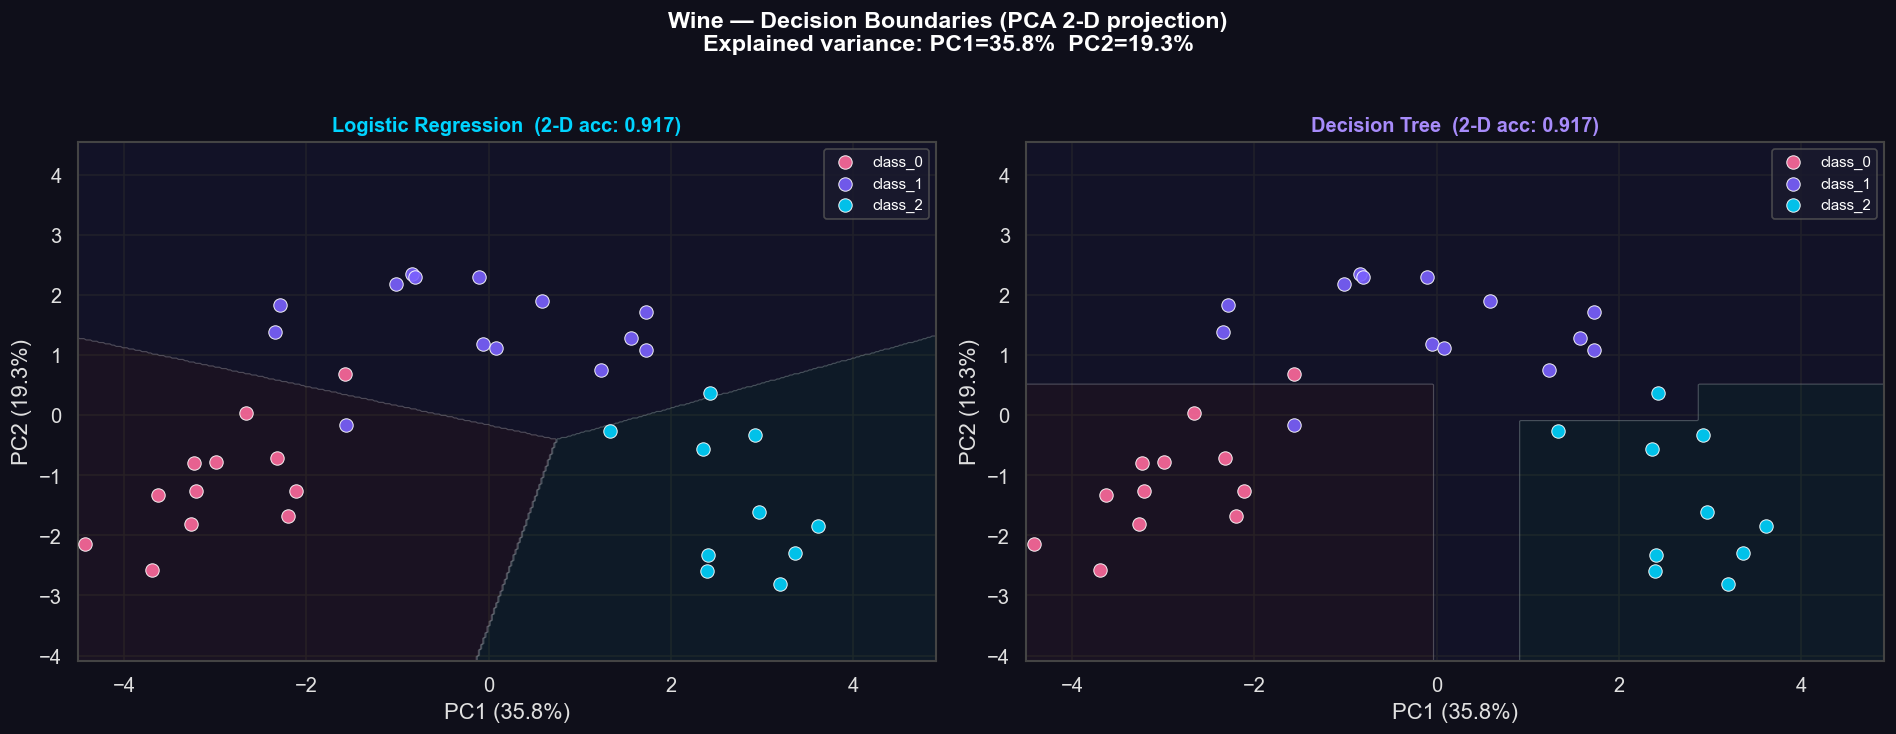

Saved → wine_decision_boundaries.png


In [12]:
def plot_decision_boundaries(dataset_name, X_train, X_test, y_train, y_test, bunch):
    """2-D PCA projection + decision boundary for LR and DT."""
    pca        = PCA(n_components=2, random_state=RANDOM_STATE)
    X_train_2d = pca.fit_transform(X_train)
    X_test_2d  = pca.transform(X_test)
    explained  = pca.explained_variance_ratio_

    class_colors = ['#FF6B9D', '#7B61FF', '#00D4FF']
    n_classes    = len(bunch.target_names)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.patch.set_facecolor('#0f0f1a')
    fig.suptitle(
        f'{dataset_name} — Decision Boundaries (PCA 2-D projection)\n'
        f'Explained variance: PC1={explained[0]:.1%}  PC2={explained[1]:.1%}',
        fontsize=14, fontweight='bold', color='white', y=1.02
    )

    margin = 0.6
    x_min, x_max = X_train_2d[:, 0].min()-margin, X_train_2d[:, 0].max()+margin
    y_min, y_max = X_train_2d[:, 1].min()-margin, X_train_2d[:, 1].max()+margin
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400),
                         np.linspace(y_min, y_max, 400))

    model_cfgs = [
        ('Logistic Regression',
         LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), '#00D4FF'),
        ('Decision Tree',
         DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE), '#A78BFA')
    ]

    for ax, (model_name, model, accent_color) in zip(axes, model_cfgs):
        model.fit(X_train_2d, y_train)
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

        bg_colors = ['#1a0a14', '#0a0a1f', '#001a1f'][:n_classes]
        bg_cmap   = ListedColormap(bg_colors)
        ax.contourf(xx, yy, Z, alpha=0.45, cmap=bg_cmap,
                    levels=np.arange(-0.5, n_classes+0.5, 1))
        ax.contour(xx, yy, Z, colors='#ffffff', linewidths=0.7, alpha=0.25,
                   levels=np.arange(-0.5, n_classes+0.5, 1))

        for cls_idx, cls_name in enumerate(bunch.target_names):
            mask = y_test == cls_idx
            ax.scatter(X_test_2d[mask, 0], X_test_2d[mask, 1],
                       c=class_colors[cls_idx], label=cls_name,
                       s=65, edgecolors='white', linewidths=0.6, alpha=0.9, zorder=3)

        acc = accuracy_score(y_test, model.predict(X_test_2d))
        ax.set_title(f'{model_name}  (2-D acc: {acc:.3f})',
                     color=accent_color, fontsize=12, fontweight='bold')
        ax.set_xlabel(f'PC1 ({explained[0]:.1%})', color='#e0e0e0')
        ax.set_ylabel(f'PC2 ({explained[1]:.1%})', color='#e0e0e0')
        ax.set_facecolor('#1a1a2e')
        ax.tick_params(colors='#e0e0e0')
        for spine in ax.spines.values():
            spine.set_edgecolor('#444')
        ax.legend(facecolor='#1a1a2e', edgecolor='#555',
                  labelcolor='white', fontsize=9, loc='upper right')

    plt.tight_layout()
    fname = f'{dataset_name.lower()}_decision_boundaries.png'
    plt.savefig(fname, bbox_inches='tight', facecolor='#0f0f1a')
    plt.show()
    print(f'Saved → {fname}')

plot_decision_boundaries('Iris', iris_X_train, iris_X_test,
                         iris_y_train, iris_y_test, iris_bunch)

plot_decision_boundaries('Wine', wine_X_train, wine_X_test,
                         wine_y_train, wine_y_test, wine_bunch)

---
## 9 · Decision Tree Structure Visualization

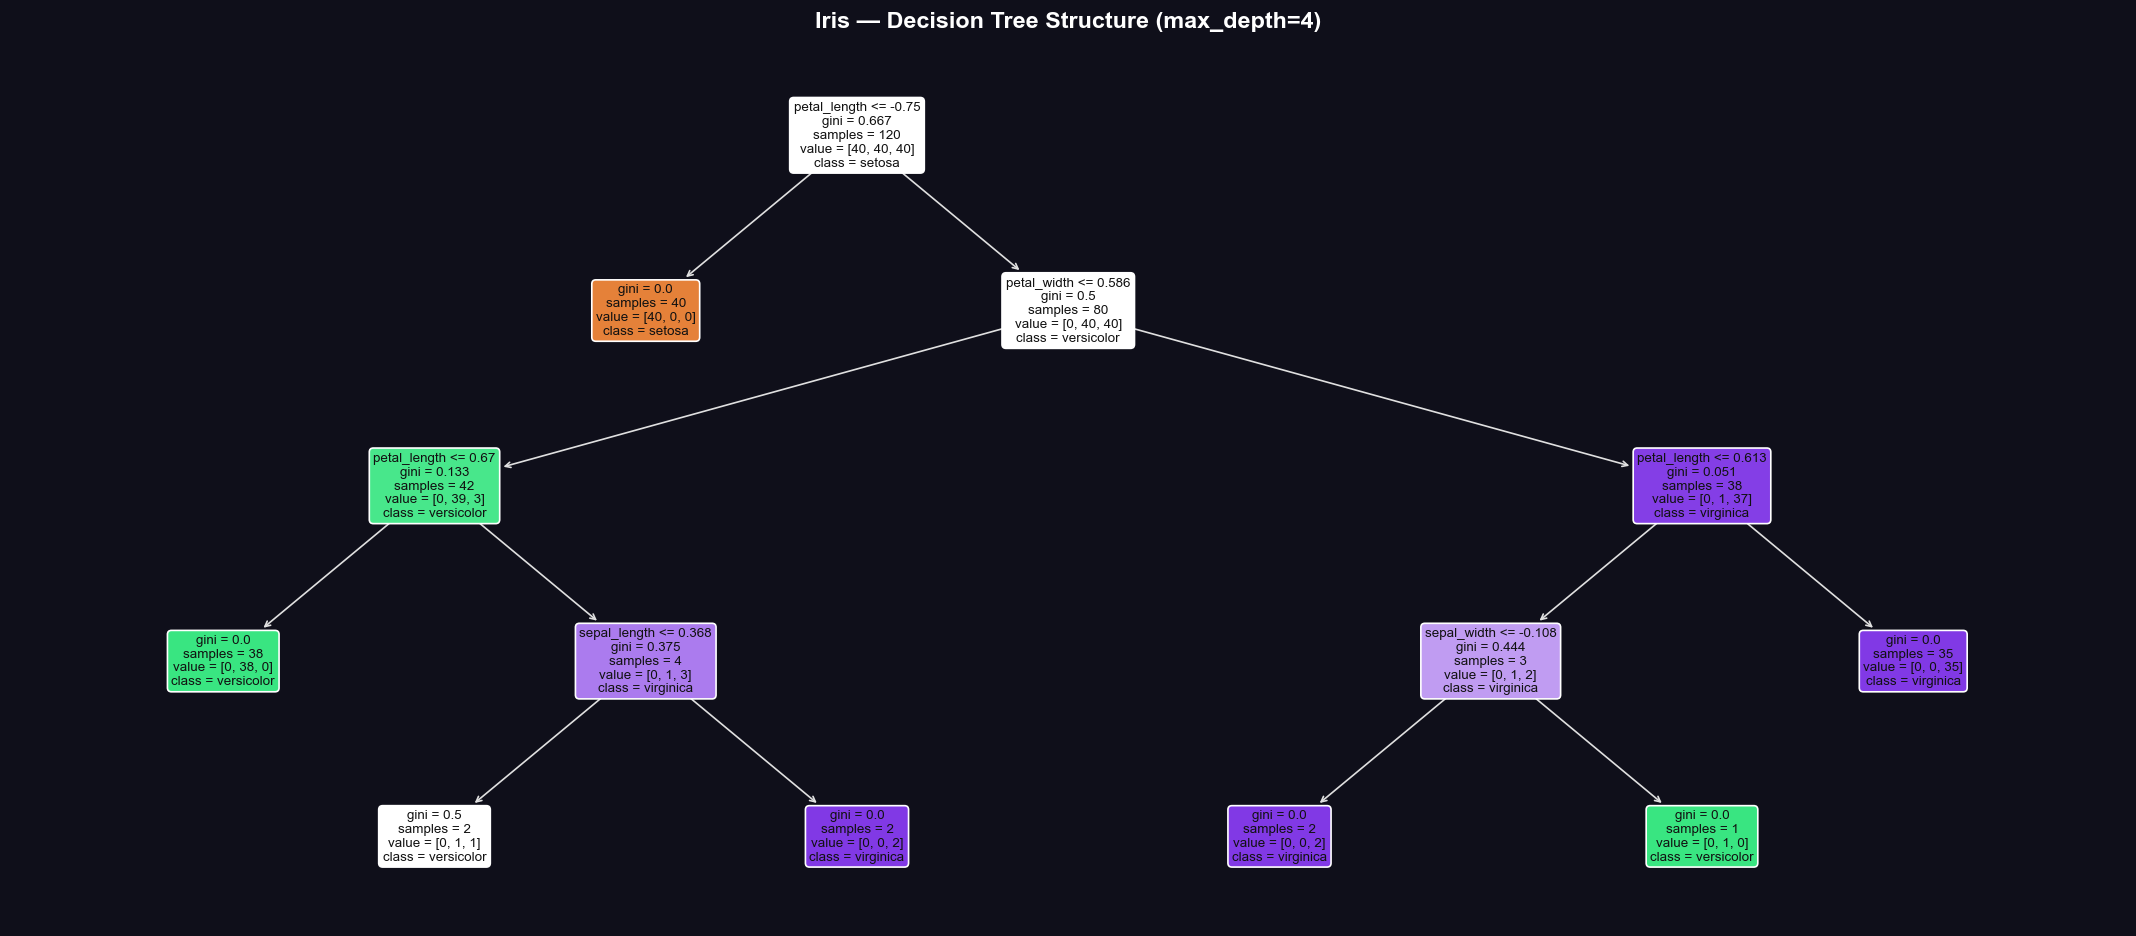

Saved → iris_decision_tree.png


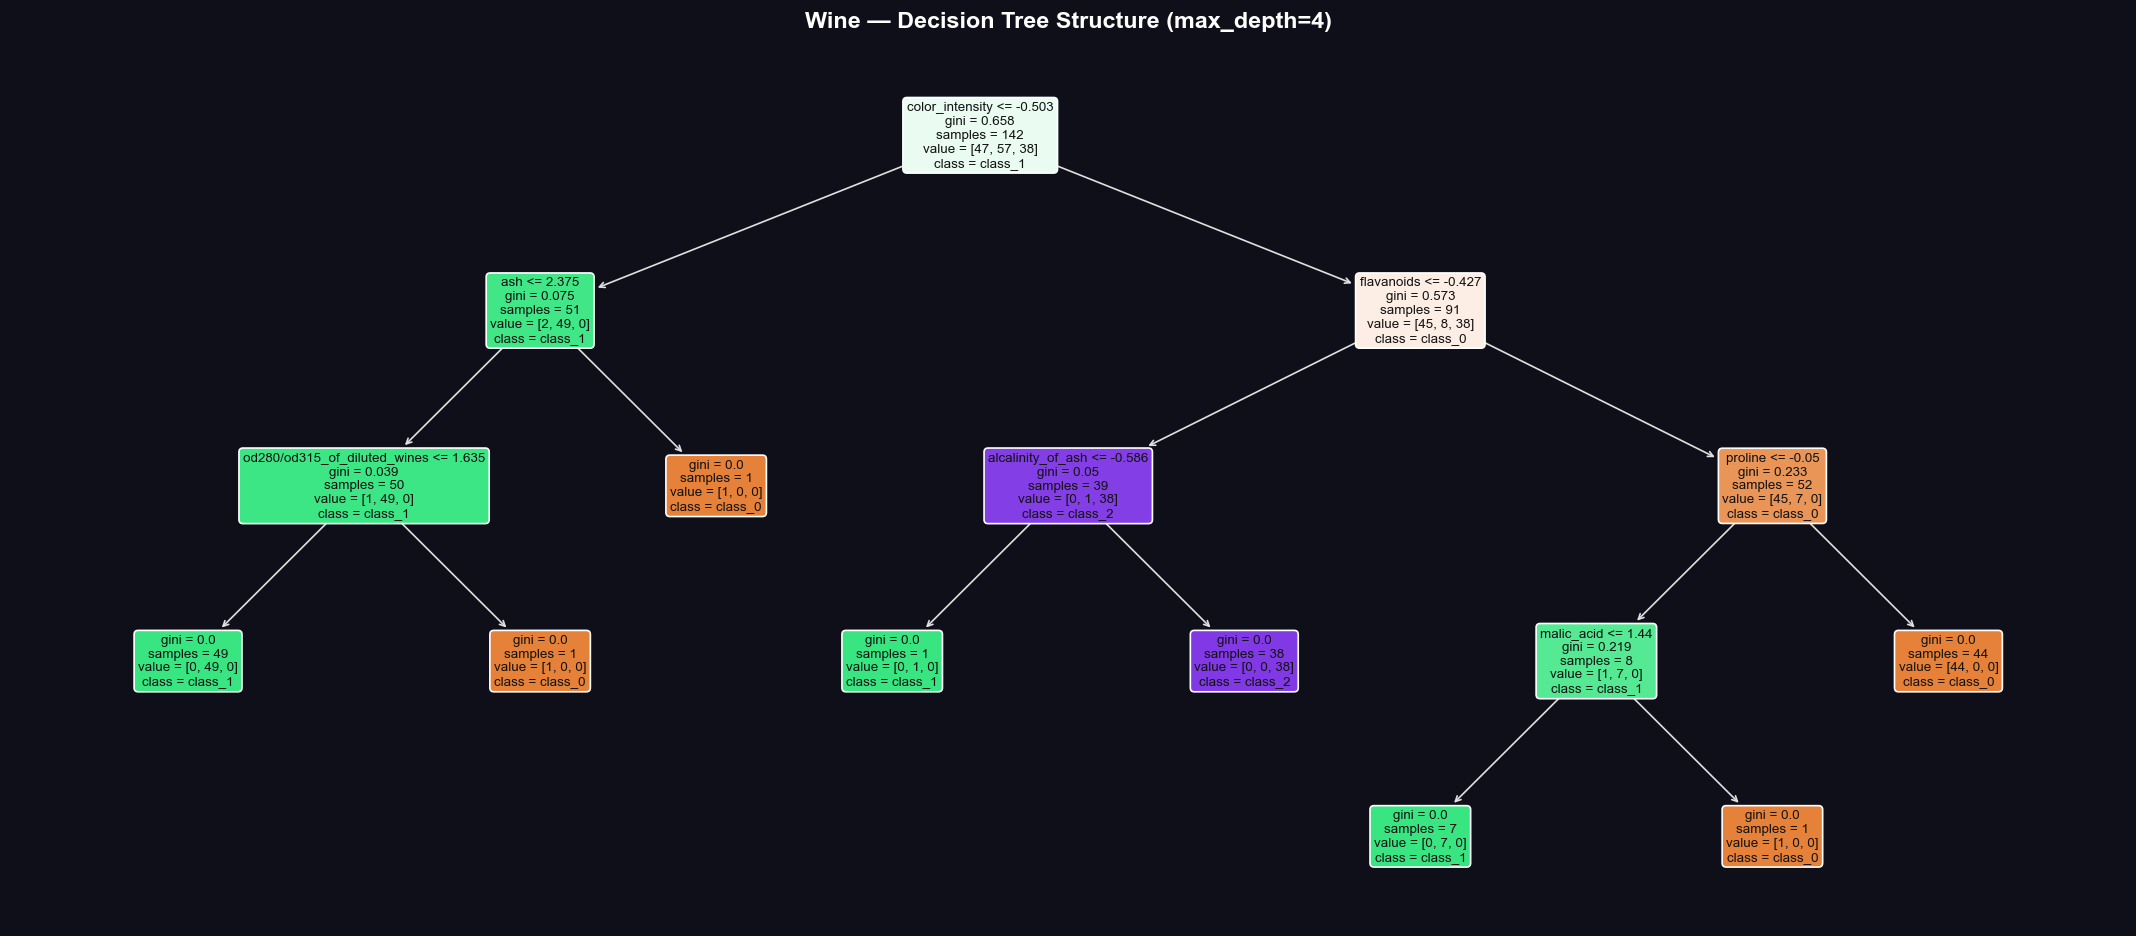

Saved → wine_decision_tree.png


In [13]:
for ds_name, (X_tr, X_te, y_tr, y_te, bunch) in datasets.items():
    dt_model = trained[ds_name]['Decision Tree']

    fig, ax = plt.subplots(figsize=(18, 8))
    fig.patch.set_facecolor('#0f0f1a')
    ax.set_facecolor('#0f0f1a')

    plot_tree(
        dt_model,
        feature_names=bunch.feature_names,
        class_names=bunch.target_names,
        filled=True, rounded=True, impurity=True,
        fontsize=8, ax=ax, proportion=False
    )
    ax.set_title(f'{ds_name} — Decision Tree Structure (max_depth=4)',
                 color='white', fontsize=14, fontweight='bold', pad=12)
    for text in ax.texts:
        text.set_color('#111')

    plt.tight_layout()
    fname = f'{ds_name.lower()}_decision_tree.png'
    plt.savefig(fname, bbox_inches='tight', facecolor='#0f0f1a')
    plt.show()
    print(f'Saved → {fname}')

---
## 10 · Feature Importance (Decision Tree)

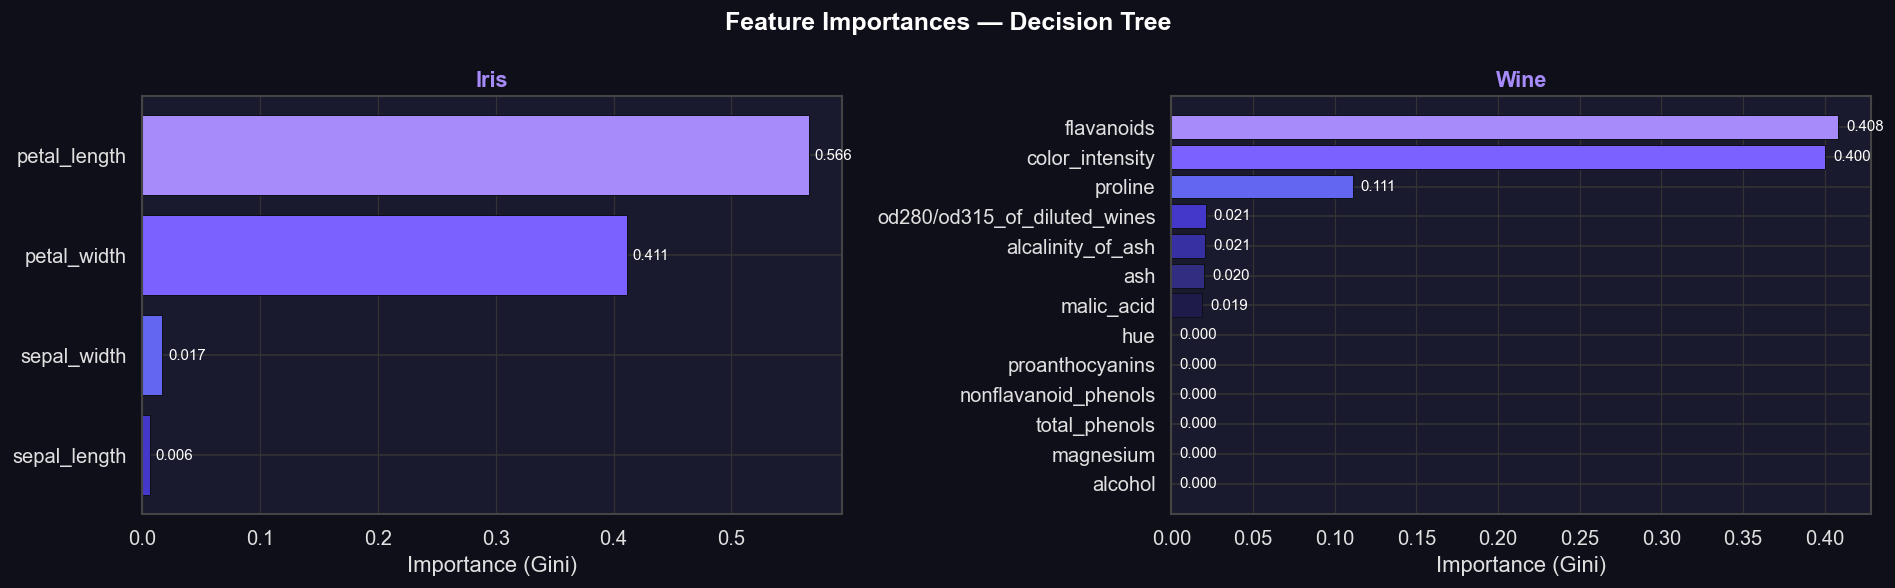

Saved → feature_importances.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.patch.set_facecolor('#0f0f1a')
fig.suptitle('Feature Importances — Decision Tree', fontsize=15,
             fontweight='bold', color='white')

for ax, (ds_name, (X_tr, X_te, y_tr, y_te, bunch)) in zip(axes, datasets.items()):
    dt_model    = trained[ds_name]['Decision Tree']
    importances = dt_model.feature_importances_
    feat_names  = bunch.feature_names

    order        = np.argsort(importances)[::-1]
    sorted_imp   = importances[order]
    sorted_names = [feat_names[i] for i in order]

    palette = ['#A78BFA', '#7B61FF', '#6366F1', '#4338CA',
               '#3730A3', '#312E81', '#1E1B4B', '#0f0f1a',
               '#0a0a14', '#060611', '#040409', '#020205', '#010102']
    bar_colors = palette[:len(sorted_imp)]

    bars = ax.barh(sorted_names[::-1], sorted_imp[::-1],
                   color=bar_colors[::-1], edgecolor='#0f0f1a', linewidth=0.6)
    for bar, val in zip(bars, sorted_imp[::-1]):
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', va='center', ha='left', color='white', fontsize=9)

    ax.set_title(f'{ds_name}', color='#A78BFA', fontsize=13, fontweight='bold')
    ax.set_xlabel('Importance (Gini)', color='#e0e0e0')
    ax.set_facecolor('#1a1a2e')
    ax.tick_params(colors='#e0e0e0')
    for spine in ax.spines.values():
        spine.set_edgecolor('#444')
    ax.xaxis.grid(True, color='#333', linewidth=0.7)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('feature_importances.png', bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
print('Saved → feature_importances.png')

---
## 11 · Final Summary

In [15]:
print('\n' + '╔' + '═'*62 + '╗')
print('║{:^62}║'.format('FINAL BENCHMARK SUMMARY'))
print('╠' + '═'*62 + '╣')
print(f'║  {"Dataset":<10} {"Model":<24} {"Acc":>7} {"Prec":>7} {"Rec":>7} {"F1":>6}  ║')
print('╠' + '─'*62 + '╣')
for _, row in metrics_df.iterrows():
    print(f'║  {row["Dataset"]:<10} {row["Model"]:<24} '
          f'{row["Accuracy"]:>7.4f} {row["Precision"]:>7.4f} '
          f'{row["Recall"]:>7.4f} {row["F1-Score"]:>6.4f}  ║')
print('╚' + '═'*62 + '╝')

print('\n📁 Saved artifacts:')
saved_files = [
    'iris_pairplot.png', 'wine_pairplot.png',
    'confusion_matrices.png', 'metrics_comparison.png',
    'iris_decision_boundaries.png', 'wine_decision_boundaries.png',
    'iris_decision_tree.png', 'wine_decision_tree.png',
    'feature_importances.png'
]
for f in saved_files:
    print(f'   • {f}')


╔══════════════════════════════════════════════════════════════╗
║                   FINAL BENCHMARK SUMMARY                    ║
╠══════════════════════════════════════════════════════════════╣
║  Dataset    Model                        Acc    Prec     Rec     F1  ║
╠──────────────────────────────────────────────────────────────╣
║  Iris       Logistic Regression       0.9333  0.9333  0.9333 0.9333  ║
║  Iris       Decision Tree             0.9333  0.9333  0.9333 0.9333  ║
║  Wine       Logistic Regression       0.9722  0.9741  0.9722 0.9720  ║
║  Wine       Decision Tree             0.9444  0.9514  0.9444 0.9450  ║
╚══════════════════════════════════════════════════════════════╝

📁 Saved artifacts:
   • iris_pairplot.png
   • wine_pairplot.png
   • confusion_matrices.png
   • metrics_comparison.png
   • iris_decision_boundaries.png
   • wine_decision_boundaries.png
   • iris_decision_tree.png
   • wine_decision_tree.png
   • feature_importances.png
